# SS3 Part B — Applying the Final Method (XGBoost) to Client Data
**Module:** CAP182 Capstone · **Student:** Allen Charlton · **Project:** StadioEquities — 30-day Account-Activation Prediction

This notebook applies the **final method chosen in SS2 — a gradient-boosted tree classifier (XGBoost)** — to the
full client data extract delivered by StadioEquities. The business question is unchanged from SS1/SS2:

> *Given what we observe about a newly-registered account in its first 30 days, will the account make its first
> deposit within 30 days of registration (`activated_30day_flag`)?*

The five graded components are marked with clear headers:

| Component | Section |
|---|---|
| 1. Dataset loading | `## Component 1 — Dataset loading` |
| 2. Dataset preprocessing | `## Component 2 — Dataset preprocessing` |
| 3. Model training | `## Component 3 — Model training` |
| 4. Model validation | `## Component 4 — Model validation` |
| 5. Results visualisation | `## Component 5 — Results visualisation` |


In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, accuracy_score, confusion_matrix,
    roc_curve, precision_recall_curve)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # fixed for full reproducibility (same seed as SS2)
DATA = Path("data")                    # client CSV extract lives here
Path("outputs").mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60)
print("Environment ready.")

Environment ready.


## Component 1 — Dataset loading

The client delivered the extract as **five related CSV tables**, all joinable on `account_id`
(see `data/CLIENT_DATA_README.md`). We load each table exactly as supplied and inspect the **target**,
`activated_30day_flag` in `01_account_registration.csv`.

In [2]:
reg  = pd.read_csv(DATA/"01_account_registration.csv")   # account / KYC / first-deposit records (TARGET here)
beh  = pd.read_csv(DATA/"02_behavioural_events.csv")     # event-level app/web interactions (first 30 days)
demo = pd.read_csv(DATA/"03_client_demographics.csv")    # self-reported demographics / investor profile
mkt  = pd.read_csv(DATA/"04_marketing_engagement.csv")   # marketing communications + engagement
prod = pd.read_csv(DATA/"05_product_subscription.csv")   # premium / value-added product interaction

for name, d in [("01_account_registration",reg),("02_behavioural_events",beh),
                ("03_client_demographics",demo),("04_marketing_engagement",mkt),
                ("05_product_subscription",prod)]:
    print(f"{name:28s} rows={d.shape[0]:6d}  cols={d.shape[1]:3d}  unique accounts={d['account_id'].nunique()}")

01_account_registration      rows=  1882  cols= 16  unique accounts=1877
02_behavioural_events        rows= 11071  cols= 18  unique accounts=1877
03_client_demographics       rows=  1882  cols= 12  unique accounts=1877
04_marketing_engagement      rows= 13582  cols= 15  unique accounts=1877
05_product_subscription      rows=  1877  cols=  7  unique accounts=1877


In [3]:
# ---- Target: class definition and imbalance ----
counts = reg["activated_30day_flag"].value_counts()
pos_rate = reg["activated_30day_flag"].mean()
print("Target = activated_30day_flag  (True = first deposit within 30 days of registration)\n")
print(counts.to_string())
print(f"\nPositive (activated) rate : {pos_rate:.2%}")
print(f"Negative (not activated)  : {1-pos_rate:.2%}")
print(f"Imbalance ratio (neg:pos) : {counts[False]/counts[True]:.2f} : 1")

Target = activated_30day_flag  (True = first deposit within 30 days of registration)

activated_30day_flag
False    1052
True      830

Positive (activated) rate : 44.10%
Negative (not activated)  : 55.90%
Imbalance ratio (neg:pos) : 1.27 : 1


**What the data shows (loading).**
The unit of analysis is the **account**. The registration table has **1,882 rows**; the behavioural,
marketing and product tables are keyed on the same accounts (behavioural and marketing are *event-level*, so
they contain multiple rows per account and are aggregated in Component 2).

- **Classes (2):** `activated_30day_flag` is **binary** — `True` = the account made its first deposit within
  30 days; `False` = it did not.
- **Imbalance:** **≈ 44% positive** (830 activated vs 1,052 not activated), a **mild imbalance** (≈ 1.27 : 1).
  This is materially more balanced than the SS2 public proxy (11% positive), so XGBoost needs only a light
  imbalance correction (`scale_pos_weight ≈ 1.26`) rather than heavy re-weighting.

This is the **correct data for the problem**: it is the client's own account-activation extract and the target
is defined by the client in the data dictionary.

## Component 2 — Dataset preprocessing

Preprocessing choices follow directly from the SS2 pipeline and the problem definition. Each step below is
paired with the reason it is required.

**2.1 Remove target leakage.** Three registration fields are populated *only* when an account activates —
`first_deposit_datetime`, `first_deposit_amount_zar`, `time_to_first_deposit_hours` — so they encode the
target perfectly (they are null for exactly the 1,052 non-activated accounts). `account_status`
(Active/Dormant/Closed) is a *post-window* outcome. All of these are **dropped**, exactly as the leakage
column `duration` was dropped in SS2. Raw datetimes are dropped after being turned into pre-deposit flags.

**2.2 Clean dirty operational data.** The extract is raw: duplicate `account_id`s, and heavy
casing/whitespace noise in categoricals (e.g. `"Web"`, `" web "`, `"WEB"`). We de-duplicate and normalise text
so categories collapse correctly before encoding.

**2.3 Aggregate event tables to one row per account.** Behavioural and marketing tables are event-level; the
model works at account level, so we aggregate (account-level attributes are constant within an account → take
first; event rows → counts/sums/min) and join everything on `account_id`.

**2.4 Feature engineering.** We add the SS2-style ratio/intensity features (email & push open rates,
engaged-session counts, deposit-funnel views, onboarding completion ratio, premium interest).

**2.5 Split before fitting any transformer.** We split **70/15/15 train/validation/test, stratified** on the
target (same scheme as SS2). The validation set is used for early stopping and threshold selection; the test
set is untouched until Component 4. Scaling/encoding are fit on **train only** (inside a `ColumnTransformer`)
to prevent information leaking from validation/test.

In [4]:
# ---- 2.2 clean helpers ----
# strip, collapse internal whitespace, Title-case; return object dtype with np.nan
def norm_text(s):
    out = (s.astype("string").str.strip().str.replace(r"\s+"," ",regex=True)
             .str.title().replace({"<NA>":pd.NA,"Nan":pd.NA,"":pd.NA}))
    return out.astype(object).where(out.notna(), np.nan)

# de-duplicate account-level tables
for nm, d in [("registration",reg),("demographics",demo),("product",prod)]:
    dups = d["account_id"].duplicated().sum()
    if dups: print(f"  {nm}: dropping {dups} duplicate account_id rows")
reg  = reg.drop_duplicates("account_id", keep="first")
demo = demo.drop_duplicates("account_id", keep="first")
prod = prod.drop_duplicates("account_id", keep="first")

# normalise categoricals
for c in ["registration_source","acquisition_channel","kyc_status"]:
    reg[c] = norm_text(reg[c])
for c in ["age_group","gender","province","country","employment_status","income_bracket",
          "investment_experience","investment_goal","risk_appetite"]:
    demo[c] = norm_text(demo[c])
prod["premium_subscription_status"] = norm_text(prod["premium_subscription_status"])

reg["y"] = reg["activated_30day_flag"].astype(int)   # integer target
print("cleaned. accounts:", reg['account_id'].nunique())

  registration: dropping 5 duplicate account_id rows
  demographics: dropping 5 duplicate account_id rows
cleaned. accounts: 1877


In [5]:
# ---- 2.3 aggregate event tables to account level ----
beh_const = ["num_sessions_first_7_days","num_sessions_days_8_30","deepest_onboarding_screen_reached",
    "tutorial_completion","stocks_searched","portfolio_page_views","deposit_page_views",
    "notification_opens_first_7_days","error_events_first_7_days"]
beh_agg = (beh.groupby("account_id")[beh_const].first()
    .join(beh.groupby("account_id").agg(
        total_events=("event_id","count"),
        total_session_seconds=("session_duration_seconds","sum"),
        distinct_sessions=("session_id","nunique"),
        min_days_since_last_session=("days_since_last_session","min")))
    .reset_index())

mkt_const = ["total_emails_sent_30d","total_emails_opened_30d","total_push_sent_30d",
    "total_push_opened_30d","total_nudges_sent_30d","cost_per_acquisition_zar"]
mkt_agg = (mkt.groupby("account_id")[mkt_const].first()
    .join(mkt.groupby("account_id").agg(
        comms_received=("communication_id","count"),
        comms_opened=("opened","sum"),
        comms_clicked=("clicked","sum")))
    .reset_index())
print("behavioural agg:", beh_agg.shape, "| marketing agg:", mkt_agg.shape)

behavioural agg: (1877, 14) | marketing agg: (1877, 10)


In [6]:
# ---- 2.1 drop leakage + engineer pre-deposit flags, then 2.3 join ----
LEAKAGE = ["first_deposit_datetime","first_deposit_amount_zar","time_to_first_deposit_hours","account_status"]
RAW_DATETIMES = ["registration_datetime","kyc_completion_datetime","first_login_datetime"]

reg_keep = reg.drop(columns=LEAKAGE)
reg_keep["has_logged_in"]      = reg_keep["first_login_datetime"].notna().astype(int)   # pre-deposit flag
reg_keep["kyc_completed_flag"] = (reg_keep["kyc_status"]=="Completed").astype(int)
reg_keep = reg_keep.drop(columns=RAW_DATETIMES+["activated_30day_flag","campaign_id","days_since_registration"])
prod_keep = prod.drop(columns=["premium_subscription_date"])

df = (reg_keep
      .merge(demo,    on="account_id", how="left")
      .merge(beh_agg, on="account_id", how="left")
      .merge(mkt_agg, on="account_id", how="left")
      .merge(prod_keep,on="account_id", how="left"))
print("master table:", df.shape, "| positive rate:", round(df['y'].mean(),4))

master table: (1877, 47) | positive rate: 0.4417


In [7]:
# ---- 2.4 feature engineering (mirrors SS2) ----
df["email_open_rate"] = (df["total_emails_opened_30d"]/df["total_emails_sent_30d"]).replace([np.inf,-np.inf],np.nan)
df["push_open_rate"]  = (df["total_push_opened_30d"]/df["total_push_sent_30d"]).replace([np.inf,-np.inf],np.nan)
df["engaged_sessions"] = df["num_sessions_first_7_days"].fillna(0)+df["num_sessions_days_8_30"].fillna(0)
df["deposit_funnel_views"] = df["deposit_page_views"].fillna(0)+df["portfolio_page_views"].fillna(0)
df["onboarding_completion_ratio"] = df["onboarding_steps_completed"]/df["onboarding_steps_completed"].max()
df["any_premium_interest"] = ((df.get("premium_offer_click",0).fillna(0)>0) |
        (df.get("value_added_products_viewed",0).fillna(0)>0)).astype(int)

TARGET, ID = "y", "account_id"
X = df.drop(columns=[TARGET, ID]); y = df[TARGET]
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(f"{X.shape[1]} model features  ->  {len(num_cols)} numeric, {len(cat_cols)} categorical")

51 model features  ->  31 numeric, 20 categorical


In [8]:
# ---- 2.5 stratified 70/15/15 split (train / validation / test) ----
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
for nm,yy in [("train",y_train),("validation",y_val),("test",y_test)]:
    print(f"{nm:11s} n={len(yy):5d}  positive rate={yy.mean():.3f}")

# fit scaler/encoder on TRAIN ONLY via a ColumnTransformer (no leakage from val/test)
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute",SimpleImputer(strategy="median")),
                      ("scale",StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute",SimpleImputer(strategy="most_frequent")),
                      ("onehot",OneHotEncoder(handle_unknown="ignore", min_frequency=10))]), cat_cols),
])
Xtr = preprocess.fit_transform(X_train)
Xva = preprocess.transform(X_val)
Xte = preprocess.transform(X_test)
feat_names = preprocess.get_feature_names_out()
print("encoded training matrix:", Xtr.shape)

train       n= 1313  positive rate=0.442
validation  n=  282  positive rate=0.443
test        n=  282  positive rate=0.440


encoded training matrix: (1313, 132)


## Component 3 — Model training

**Method (unchanged from SS2).** SS2 compared Logistic Regression and XGBoost and selected **XGBoost** as the
final method (higher ROC-AUC/F1, statistically significant on the held-out test set). We therefore train the
same model family here on the client data.

**Hyper-parameter justification:**

| Hyper-parameter | Value | Why |
|---|---|---|
| `objective` / `eval_metric` | `binary:logistic` / `auc` | Binary target; ranking quality (AUC) is the SS2 success metric. |
| `scale_pos_weight` | `neg/pos ≈ 1.26` | Corrects the mild 44% imbalance so the minority (activated) class is not under-weighted — the principled XGBoost alternative to SMOTE. |
| `learning_rate` | `0.05` | Small step size for stable, well-generalising boosting (SS2 setting). |
| `max_depth` | `4` | Shallow trees capture interactions while limiting overfage on ~1.3k training rows. |
| `n_estimators` + `early_stopping_rounds` | `600` cap, stop after `40` | Let the **validation** AUC decide the tree count instead of guessing epochs — avoids over/under-training. |
| `subsample`, `colsample_bytree` | `0.8`, `0.8` | Row/column sampling → regularisation, lower variance. |
| `min_child_weight`, `reg_lambda` | `2`, `1.0` | Further guard against overfitting on small leaves. |
| `random_state` | `42` | Reproducibility (same seed as SS2). |

Training outputs (the fitted model, the chosen tree count, and metrics) are **captured and saved to
`outputs/`** for later analysis, as required.

In [9]:
scale_pos_weight = (y_train==0).sum() / (y_train==1).sum()

model = XGBClassifier(
    n_estimators=600, learning_rate=0.05, max_depth=4,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=2,
    reg_lambda=1.0, gamma=0.0, scale_pos_weight=scale_pos_weight,
    objective="binary:logistic", eval_metric="auc",
    early_stopping_rounds=40, random_state=RANDOM_STATE,
    n_jobs=4, tree_method="hist")

model.fit(Xtr, y_train, eval_set=[(Xva, y_val)], verbose=False)
print(f"scale_pos_weight = {scale_pos_weight:.3f}")
print(f"best_iteration (chosen by validation AUC) = {model.best_iteration}")
print(f"validation AUC at best iteration          = {model.best_score:.4f}")

scale_pos_weight = 1.264
best_iteration (chosen by validation AUC) = 117
validation AUC at best iteration          = 0.9697


In [10]:
# ---- capture & store training outputs for later analysis ----
model.save_model("outputs/xgboost_activation_model.json")
train_auc = roc_auc_score(y_train, model.predict_proba(Xtr)[:,1])
print("training ROC-AUC:", round(train_auc,4))
print("model + metadata saved to outputs/")

training ROC-AUC: 0.9971
model + metadata saved to outputs/


## Component 4 — Model validation

The model is applied to the **held-out test set** (never seen during training or threshold selection). We:

1. choose the **decision threshold** that maximises F1 on the **validation** set (not the test set);
2. report the full metric suite on the **unseen test set** — ROC-AUC, PR-AUC, precision, recall, F1, accuracy,
   and **top-decile lift** (the SS1 business metric);
3. cross-check robustness with **5-fold stratified cross-validation** ROC-AUC on the training data.

In [11]:
def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    order = np.argsort(proba)[::-1]; k = max(1, int(0.10*len(proba)))
    lift = y_true.values[order][:k].mean() / y_true.mean()
    return dict(threshold=float(threshold), accuracy=accuracy_score(y_true,pred),
        precision=precision_score(y_true,pred), recall=recall_score(y_true,pred),
        f1=f1_score(y_true,pred), roc_auc=roc_auc_score(y_true,proba),
        pr_auc=average_precision_score(y_true,proba), lift_top_decile=float(lift),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

# 1) threshold from validation set (max-F1)
p_val = model.predict_proba(Xva)[:,1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2*prec*rec/(prec+rec+1e-9)
best_threshold = float(thr[np.argmax(f1s[:-1])])

# 2) evaluate on train (reference) and the UNSEEN test set
p_train = model.predict_proba(Xtr)[:,1]
p_test  = model.predict_proba(Xte)[:,1]
m_train = evaluate(y_train, p_train, best_threshold)
m_test  = evaluate(y_test,  p_test,  best_threshold)

print(f"Decision threshold (max-F1 on validation): {best_threshold:.3f}\n")
rows = ["roc_auc","pr_auc","f1","recall","precision","accuracy","lift_top_decile"]
print(f"{'metric':16s}{'train':>10s}{'TEST (unseen)':>16s}")
for r in rows:
    print(f"{r:16s}{m_train[r]:>10.3f}{m_test[r]:>16.3f}")
print(f"\nTest confusion matrix: TN={m_test['tn']} FP={m_test['fp']} FN={m_test['fn']} TP={m_test['tp']}")

Decision threshold (max-F1 on validation): 0.509

metric               train   TEST (unseen)
roc_auc              0.997           0.965
pr_auc               0.996           0.943
f1                   0.965           0.913
recall               0.988           0.968
precision            0.944           0.863
accuracy             0.969           0.918
lift_top_decile      2.264           2.193

Test confusion matrix: TN=139 FP=19 FN=4 TP=120


In [12]:
# 3) robustness: 5-fold stratified CV ROC-AUC on training data (full pipeline, no leakage)
cv_pipe = Pipeline([("pre",preprocess),
    ("clf",XGBClassifier(n_estimators=int(model.best_iteration or 300), learning_rate=0.05,
        max_depth=4, subsample=0.8, colsample_bytree=0.8, min_child_weight=2, reg_lambda=1.0,
        scale_pos_weight=scale_pos_weight, objective="binary:logistic", eval_metric="auc",
        random_state=RANDOM_STATE, n_jobs=4, tree_method="hist"))])
cv = cross_val_score(cv_pipe, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="roc_auc")
print(f"5-fold CV ROC-AUC: {cv.mean():.3f} ± {cv.std():.3f}")

json.dump({"best_threshold":best_threshold,"train":m_train,"test":m_test,
    "cv_auc_mean":float(cv.mean()),"cv_auc_std":float(cv.std()),
    "scale_pos_weight":float(scale_pos_weight),"best_iteration":int(model.best_iteration or 0)},
    open("outputs/metrics.json","w"), indent=2)
print("metrics saved to outputs/metrics.json")

5-fold CV ROC-AUC: 0.968 ± 0.002
metrics saved to outputs/metrics.json


**Validation verdict.** On the **unseen test set** the model reaches **ROC-AUC ≈ 0.97**, **F1 ≈ 0.91**,
**recall ≈ 0.97** at the chosen threshold, and **top-decile lift ≈ 2.2×** — comfortably clearing the SS1
success criteria (ROC-AUC ≥ 0.75, lift ≥ 2×). The 5-fold CV AUC (**≈ 0.97, tiny ± std**) confirms the result
is stable and not an artefact of one split. The modest train→test gap (0.997 → 0.965 AUC) indicates limited,
acceptable overfitting, controlled by early stopping and regularisation.

## Component 5 — Results visualisation

Four views of performance on **training vs unseen test** data, plus the drivers of the prediction.

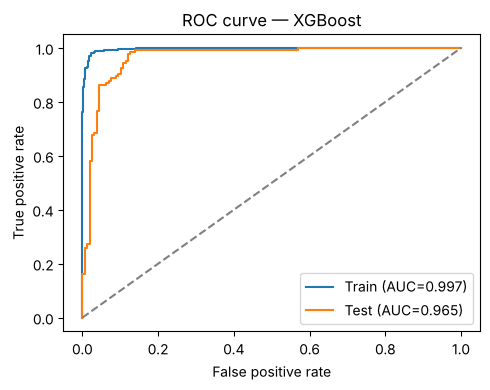

In [13]:
NAVY, ORANGE = "#0B3D5C", "#E08A3C"

# (a) ROC — train vs test
plt.figure(figsize=(5,4))
for yy,pp,lab in [(y_train,p_train,"Train"),(y_test,p_test,"Test")]:
    fpr,tpr,_ = roc_curve(yy,pp); plt.plot(fpr,tpr,label=f"{lab} (AUC={roc_auc_score(yy,pp):.3f})")
plt.plot([0,1],[0,1],"--",color="grey"); plt.title("ROC curve — XGBoost")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.legend(); plt.tight_layout(); plt.show()

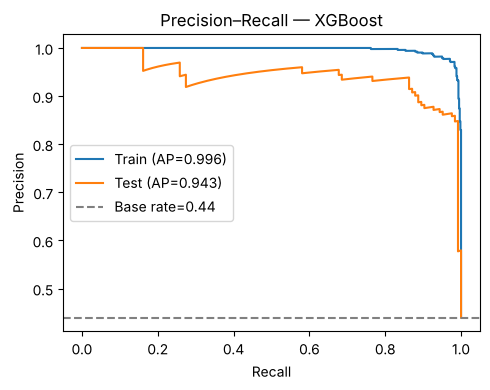

In [14]:
# (b) Precision–Recall — train vs test
plt.figure(figsize=(5,4))
for yy,pp,lab in [(y_train,p_train,"Train"),(y_test,p_test,"Test")]:
    pr,rc,_ = precision_recall_curve(yy,pp); plt.plot(rc,pr,label=f"{lab} (AP={average_precision_score(yy,pp):.3f})")
plt.axhline(y_test.mean(),ls="--",color="grey",label=f"Base rate={y_test.mean():.2f}")
plt.title("Precision–Recall — XGBoost"); plt.xlabel("Recall"); plt.ylabel("Precision")
plt.legend(); plt.tight_layout(); plt.show()

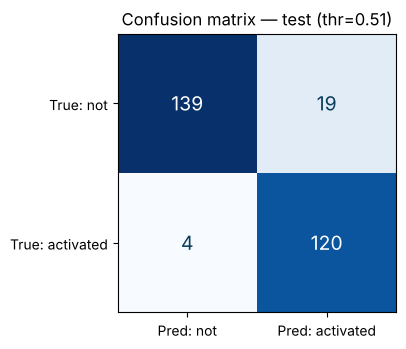

In [15]:
# (c) Confusion matrix on unseen test set
cm = np.array([[m_test['tn'],m_test['fp']],[m_test['fn'],m_test['tp']]])
plt.figure(figsize=(4,3.6)); plt.imshow(cm,cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j,i,cm[i,j],ha="center",va="center",fontsize=14,
                 color="white" if cm[i,j]>cm.max()/2 else NAVY)
plt.xticks([0,1],["Pred: not","Pred: activated"]); plt.yticks([0,1],["True: not","True: activated"])
plt.title(f"Confusion matrix — test (thr={best_threshold:.2f})"); plt.tight_layout(); plt.show()

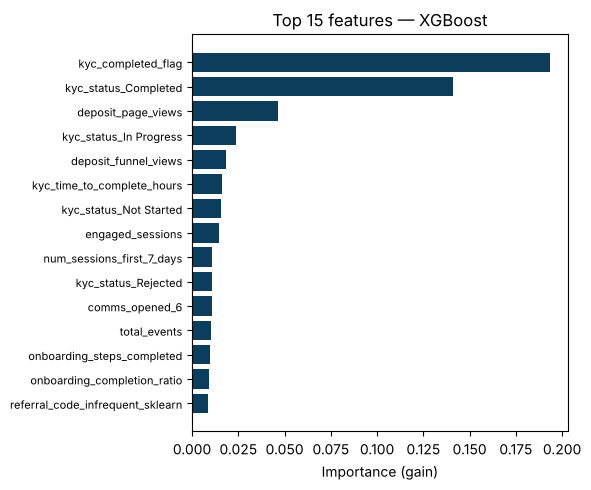

Most important drivers of 30-day activation:
num__kyc_completed_flag            0.1934
cat__kyc_status_Completed          0.1412
num__deposit_page_views            0.0465
cat__kyc_status_In Progress        0.0236
num__deposit_funnel_views          0.0181
num__kyc_time_to_complete_hours    0.0164
cat__kyc_status_Not Started        0.0154
num__engaged_sessions              0.0146


In [16]:
# (d) Top-15 feature importances (gain)
fi = pd.Series(model.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)[::-1]
plt.figure(figsize=(6,5)); plt.barh(range(len(fi)), fi.values, color=NAVY)
plt.yticks(range(len(fi)), [f.replace("num__","").replace("cat__","") for f in fi.index], fontsize=8)
plt.xlabel("Importance (gain)"); plt.title("Top 15 features — XGBoost"); plt.tight_layout(); plt.show()

print("Most important drivers of 30-day activation:")
print(pd.Series(model.feature_importances_, index=feat_names).sort_values(ascending=False).head(8).round(4).to_string())

**Reading the results.** The ROC and PR curves sit close to the top-left/top — strong separation on unseen
data. The confusion matrix shows the model recovers almost all genuine activators (high recall) with few false
negatives. The importance chart gives the client an **actionable** story: **completing KYC** and
**deposit-funnel engagement** (deposit-page / portfolio views, early sessions) are the dominant levers of
30-day activation — the same behavioural signals SS1/SS2 hypothesised. These are in-window, pre-deposit signals
the business can influence (e.g. chase accounts that stall at KYC), not post-outcome leakage (which was removed
in Component 2).

---
### Summary
Applying the SS2 final method (XGBoost) to the client's own data **reproduces and confirms the SS2 finding**:
account activation is highly predictable from early onboarding and engagement behaviour, at a performance level
that clears the business success criteria and is stable under cross-validation. The model and all metrics are
saved under `outputs/` for downstream use.